In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
url = "https://zenodo.org/records/18338186/files/Student%20Performance%20Factors.csv?download=1"

df = pd.read_csv(url)

print("Dataset berhasil dibaca!")
print("Jumlah baris dan kolom:", df.shape)

display(df.head())

Dataset berhasil dibaca!
Jumlah baris dan kolom: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [3]:
print("Informasi Dataset:")
df.info()

print("\nJumlah data kosong:")
print(df.isnull().sum())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6

In [4]:
np.random.seed(42)

sampel_df = df[['Hours_Studied']].sample(
    n=100,
    random_state=42
)

sampel = sampel_df['Hours_Studied'].to_numpy()

print("Data 100 Sampel:")
display(sampel_df)

print("Jumlah sampel:", len(sampel))

Data 100 Sampel:


,Hours_Studied
743,20
5551,22
3442,21
6571,12
4204,21
...,...
5482,20
4545,24
2859,21
2684,22


Jumlah sampel: 100


In [5]:
n = len(sampel)

rata_rata = np.mean(sampel)
standar_deviasi = np.std(sampel, ddof=1)

print("Jumlah sampel:", n)
print("Rata-rata:", rata_rata)
print("Standar deviasi:", standar_deviasi)
print("Nilai minimum:", np.min(sampel))
print("Nilai maksimum:", np.max(sampel))

Jumlah sampel: 100
Rata-rata: 19.94
Standar deviasi: 6.442943050463441
Nilai minimum: 3
Nilai maksimum: 39


In [6]:
estimasi_titik = np.mean(sampel)

print("HASIL ESTIMASI TITIK")
print("Estimasi rata-rata populasi:", estimasi_titik)

HASIL ESTIMASI TITIK
Estimasi rata-rata populasi: 19.94


In [7]:
# Estimasi interval menggunakan distribusi Z

z = 1.96
standard_error = standar_deviasi / np.sqrt(n)

margin_error = z * standard_error

batas_bawah = rata_rata - margin_error
batas_atas = rata_rata + margin_error

print("HASIL ESTIMASI INTERVAL 95%")
print("Standard Error:", standard_error)
print("Margin Error:", margin_error)
print("Batas Bawah:", batas_bawah)
print("Batas Atas:", batas_atas)
print("Interval Kepercayaan:",
      (batas_bawah, batas_atas))

HASIL ESTIMASI INTERVAL 95%
Standard Error: 0.6442943050463441
Margin Error: 1.2628168378908344
Batas Bawah: 18.677183162109166
Batas Atas: 21.202816837890836
Interval Kepercayaan: (np.float64(18.677183162109166), np.float64(21.202816837890836))


In [8]:
# Resampling Jackknife

hasil_jackknife = []

for i in range(n):
    data_jackknife = np.delete(sampel, i)
    rata_jackknife = np.mean(data_jackknife)
    hasil_jackknife.append(rata_jackknife)

# Menghitung rata-rata hasil Jackknife
rata_jackknife = np.mean(hasil_jackknife)

print("HASIL JACKKNIFE")
print("Jumlah iterasi:", len(hasil_jackknife))
print("Rata-rata Jackknife:", rata_jackknife)

HASIL JACKKNIFE
Jumlah iterasi: 100
Rata-rata Jackknife: 19.939999999999998


In [9]:
# Proses Bootstrapping
np.random.seed(42)

hasil_bootstrap = []

for i in range(1000):
    data_bootstrap = np.random.choice(
        sampel, size=n, replace=True
    )

    rata_bootstrap = np.mean(data_bootstrap)
    hasil_bootstrap.append(rata_bootstrap)

# Menghitung rata-rata hasil Bootstrap
rata_bootstrap = np.mean(hasil_bootstrap)

print("HASIL BOOTSTRAPPING")
print("Jumlah iterasi:", len(hasil_bootstrap))
print("Rata-rata Bootstrapping:", rata_bootstrap)

HASIL BOOTSTRAPPING
Jumlah iterasi: 1000
Rata-rata Bootstrapping: 19.94494


In [10]:
# Membuat tabel perbandingan

perbandingan = pd.DataFrame({
    'Metode': ['Jackknife', 'Bootstrapping'],
    'Jumlah Iterasi': [
        len(hasil_jackknife),
        len(hasil_bootstrap)
    ],
    'Rata-rata': [
        rata_jackknife,
        rata_bootstrap
    ]
})

display(perbandingan)

,Metode,Jumlah Iterasi,Rata-rata
0,Jackknife,100,19.94000
1,Bootstrapping,1000,19.94494


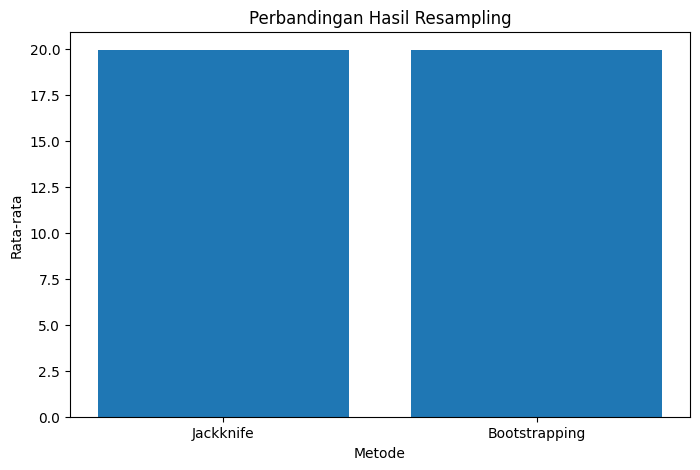

In [11]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['Jackknife', 'Bootstrapping'],
    [rata_jackknife, rata_bootstrap]
)

plt.title('Perbandingan Hasil Resampling')
plt.ylabel('Rata-rata')
plt.xlabel('Metode')

plt.show()